In [1]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from osgeo import gdal, osr
import warnings
warnings.filterwarnings('ignore')

# Set display options
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10

In [2]:
## data download

#GUNW products
# !wget https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GUNW_PROVISIONAL_V1/NISAR_L2_PR_GUNW_022_162_A_007_023_4000_SH_20260613T100656_20260613T100731_20260625T100655_20260625T100730_P05023_N_F_J_001/NISAR_L2_PR_GUNW_022_162_A_007_023_4000_SH_20260613T100656_20260613T100731_20260625T100655_20260625T100730_P05023_N_F_J_001.h5

In [3]:
## file

# For this tutorial, we'll use a sample file path
gunw_file = 'NISAR_L2_PR_GUNW_022_162_A_007_023_4000_SH_20260613T100656_20260613T100731_20260625T100655_20260625T100730_P05023_N_F_J_001.h5'

print(f"GUNW file: {gunw_file}")

output_dir = "output_files/"
os.makedirs(output_dir, exist_ok=True)

## read phase, coherence, ionoshere_phase, connected components

def read_data(filename, polarization='HH'):
    """
    Read and display unwrapped phase
    """
    with h5py.File(filename, 'r') as f:
        # Read unwrapped phase
        phase_path = f'/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}/unwrappedPhase'
        phase = f[phase_path][:]

        ## coherence
        base_path = f'/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}'
        coherence = f[f'{base_path}/coherenceMagnitude'][:]

        ## ionosphere
        iono = f[f'{base_path}/ionospherePhaseScreen'][:]
        iono_unc = f[f'{base_path}/ionospherePhaseScreenUncertainty'][:]

        ## connected components
        cc = f[f'{base_path}/connectedComponents'][:]
        
        # Read coordinates
        x = f[f'/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}/xCoordinates'][:]
        y = f[f'/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}/yCoordinates'][:]
        dx = f[f"/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}/xCoordinateSpacing"][()]
        dy = f[f"/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}/yCoordinateSpacing"][()]
        
        #read the projection information for the frequencyA grid
        projection = f[f"/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}/projection"][()]
        
        # Read attributes
        attrs = dict(f[phase_path].attrs)        
    
    return phase, coherence, iono, iono_unc, cc, x, y, dx, dy, projection

# Example usage:
phase, coherence, iono, iono_unc, cc, x, y, dx, dy, projection = read_data(gunw_file, polarization='HH')

wrapped_phase = np.angle(np.exp(1J*phase))
iono_wrapped = np.angle(np.exp(1J*iono))

GUNW file: NISAR_L2_PR_GUNW_022_162_A_007_023_4000_SH_20260613T100656_20260613T100731_20260625T100655_20260625T100730_P05023_N_F_J_001.h5


In [4]:
def parse_mask(mask_value):
    """
    Decodes a 32-bit GUNW subswath and data anomaly mask.
    """
    
    # Bits 0–7: Subswath and Water encoding
    subswath_byte = mask_value & 0xFF
    
    # Extract digits from the 0-255 byte
    is_water = (subswath_byte // 100) == 1
    ref_subswath = (subswath_byte // 10) % 10
    sec_subswath = subswath_byte % 10
    
    # Bits 8–15: Secondary RSLC anomaly flags
    sec_anomaly = (mask_value >> 8) & 0xFF

    # Bits 16–23: Reference RSLC anomaly flags
    ref_anomaly = (mask_value >> 16) & 0xFF

    iono_mask = (mask_value >> 24) & 1
    
    # Bits 24–31: Reserved for future use
    reserved = (mask_value >> 25) & 0xFF

    binary_mask_ref = (ref_subswath > 0).astype(int)    
    binary_mask_sec = (sec_subswath > 0).astype(int)  
    
    return {
        "is_water": is_water,
        "ref_subswath": binary_mask_ref,
        "sec_subswath": binary_mask_sec,
        "sec_anomaly_raw": sec_anomaly,
        "ref_anomaly_raw": ref_anomaly,
        "is_valid_subswath": (ref_subswath > 0) & (sec_subswath > 0),
        "no_anomalies": (ref_anomaly == 0) & (sec_anomaly == 0),
        "iono_mask": iono_mask
    }


with h5py.File(gunw_file, 'r') as f:
    mask_path = '/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/mask'
    mask_values = f[mask_path][:]
    mask_dict = parse_mask(mask_values)


combined_valid_mask = (
    ~mask_dict["is_water"] & 
    mask_dict["is_valid_subswath"] & 
    mask_dict["no_anomalies"]
)

phase_masked = np.where(combined_valid_mask, phase, np.nan)
wrapped_phase_masked = np.where(combined_valid_mask, wrapped_phase, np.nan)
iono_masked = np.where(combined_valid_mask, iono, np.nan)

phase_iono_corrected = phase - iono
phase_iono_corrected_masekd = np.where(combined_valid_mask, phase_iono_corrected, np.nan)

In [5]:
def read_gunw_grid_info(gunw_file, polarization='HH'):
    """
    Read grid information from GUNW product
    
    Parameters:
    -----------
    gunw_file : str
        Path to GUNW HDF5 file
    polarization : str
        Polarization (HH or VV)
    
    Returns:
    --------
    grid_info : dict
        Dictionary containing:
        - x_coords: X coordinates (easting)
        - y_coords: Y coordinates (northing)
        - epsg: EPSG code
        - projection_wkt: Projection in WKT format
        - bbox: Bounding box (xmin, ymin, xmax, ymax)
        - shape: Grid shape (ny, nx)
    """
    with h5py.File(gunw_file, 'r') as f:
        base_path = f'/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}'
        
        # Read coordinates
        x_coords = f[f'{base_path}/xCoordinates'][:]
        y_coords = f[f'{base_path}/yCoordinates'][:]
        
        # Read projection
        projection = f[f'{base_path}/projection'][()]
        #if isinstance(projection, bytes):
        #    projection = projection.decode('utf-8')
        
        # Read sample data to get shape
        sample_data = f[f'{base_path}/unwrappedPhase']
        shape = sample_data.shape
    
    # Extract EPSG code from projection
    #srs = osr.SpatialReference()
    #srs.ImportFromWkt(projection)
    #epsg = None
    #if srs.GetAuthorityName(None) == 'EPSG':
    #    epsg = int(srs.GetAuthorityCode(None))
    epsg = int(projection)
    # Calculate bounding box
    bbox = {
        'xmin': x_coords.min(),
        'xmax': x_coords.max(),
        'ymin': y_coords.min(),
        'ymax': y_coords.max()
    }
    
    grid_info = {
        'x_coords': x_coords,
        'y_coords': y_coords,
        'epsg': epsg,
        'projection_wkt': projection,
        'bbox': bbox,
        'shape': shape,
        'x_spacing': np.median(np.diff(x_coords)),
        'y_spacing': np.median(np.diff(y_coords))
    }
 
    return grid_info

# Example usage:
# gunw_file = 'data/colombia/NISAR_L2_PR_GUNW_025_011_D_086_026_4000_SH_20260708T232913_20260708T232947_20260720T232912_20260720T232946_P05023_N_F_J_001.h5'
grid_info = read_gunw_grid_info(gunw_file, polarization='HH')

from osgeo import gdal, osr

def get_gunw_bbox_latlon(hdf5_file_path: str) -> dict:
    """
    Extracts the WGS 84 (Lat/Lon) bounding box from a NISAR L2 GUNW product.
    Automatically handles any native projection (e.g., UTM grids).
    
    Parameters:
        hdf5_file_path (str): Path to the NISAR L2 GUNW HDF5 file.
        
    Returns:
        dict: A dictionary containing min/max latitude and longitude values.
    """
    # Subdataset path template matching standard NISAR L2 layout
    subdataset_path = f"NETCDF:{hdf5_file_path}://science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/HH/unwrappedPhase"
    
    # Open the dataset via GDAL
    ds = gdal.Open(subdataset_path)
    if ds is None:
        raise FileNotFoundError(f"Could not open standard NISAR subdataset at: {subdataset_path}")
        
    # Extract dimensions and transformation matrix
    width = ds.RasterXSize
    height = ds.RasterYSize
    gt = ds.GetGeoTransform()  
    
    # Compute the 4 native corners (Upper Left, Lower Left, Lower Right, Upper Right)
    native_corners = [
        (gt[0], gt[3]),                                      # UL
        (gt[0] + height * gt[2], gt[3] + height * gt[5]),    # LL
        (gt[0] + width * gt[1] + height * gt[2], gt[3] + width * gt[4] + height * gt[5]), # LR
        (gt[0] + width * gt[1], gt[3] + width * gt[4])       # UR
    ]
    
    # Initialize Spatial Reference Objects
    src_srs = osr.SpatialReference(wkt=ds.GetProjection())
    tgt_srs = osr.SpatialReference()
    tgt_srs.ImportFromEPSG(4326)  # WGS 84 target standard
    
    # Enforce GIS order (X=Longitude, Y=Latitude)
    src_srs.SetAxisMappingStrategy(osr.OAMS_TRADITIONAL_GIS_ORDER)
    tgt_srs.SetAxisMappingStrategy(osr.OAMS_TRADITIONAL_GIS_ORDER)
    
    transform = osr.CoordinateTransformation(src_srs, tgt_srs)
    
    # Transform native coordinates to Geographic Lat/Lon
    lons = []
    lats = []
    for x, y in native_corners:
        lon, lat, _ = transform.TransformPoint(x, y)
        lons.append(lon)
        lats.append(lat)
        
    # Explicit resource cleanup for GDAL pointer
    ds = None
    
    # Return bounding box dictionary
    return {
        "lon_min": min(lons),
        "lat_min": min(lats),
        "lon_max": max(lons),
        "lat_max": max(lats)
    }

# --- Example Usage ---
# file_path = "NISAR_L2_PR_GUNW_...h5"
bbox = get_gunw_bbox_latlon(gunw_file)
print(bbox)

import rasterio
from dem_stitcher.stitcher import stitch_dem

# Format into the standard list layout: [xmin, ymin, xmax, ymax]
bounds = [bbox["lon_min"], bbox["lat_min"], bbox["lon_max"], bbox["lat_max"]]

#Download and stitch the DEM over your exact bounding box
# 'glo_30' retrieves the 30-meter Copernicus Global DEM
print("Downloading and stitching DEM tiles...")
dem_array, dem_profile = stitch_dem(
    bounds,
    dem_name='glo_30',
    dst_ellipsoidal_height=True,  # Set to True if you need ellipsoidal heights instead of geoid
    dst_area_or_point='Point'
)

# 3. Export the stitched array directly to a local GeoTIFF file
output_dem_path = "nisar_gunw_dem.tif"
with rasterio.open(output_dem_path, 'w', **dem_profile) as dst:
    dst.write(dem_array, 1)

print(f"DEM successfully downloaded and saved to: {output_dem_path}")
print(f"DEM Shape: {dem_array.shape}")


def reproject_dem_to_bbox(input_dem_path, output_dem_path, target_epsg, bbox, target_width, target_height):
    """
    Reprojects a DEM using exact target pixel dimensions to guarantee matching grid shapes.
    """
    src_ds = gdal.Open(input_dem_path)
    if src_ds is None:
        raise FileNotFoundError(f"Could not open input DEM at {input_dem_path}")
        

    # Define warp options using width and height instead of xRes and yRes
    warp_options = gdal.WarpOptions(
        dstSRS=f'EPSG:{target_epsg}',
        outputBounds=bbox,              # [minx, miny, maxx, maxy]
        width=target_width,             # Exact pixel width of target GUNW layer
        height=target_height,           # Exact pixel height of target GUNW layer
        resampleAlg=gdal.GRIORA_Bilinear,
        dstNodata=-9999                 
    )

    gdal.Warp(output_dem_path, src_ds, options=warp_options)
    src_ds = None
    print(f"Successfully reprojected DEM saved to: {output_dem_path}")


input_dem = "nisar_gunw_dem.tif"
gunw_dem = "NISAR_GUNW_DEM.tif"
output_bbox = [grid_info['bbox']['xmin'], grid_info['bbox']['ymin'], grid_info['bbox']['xmax'], grid_info['bbox']['ymax']]
target_res = grid_info['x_spacing']

reproject_dem_to_bbox(
    input_dem, 
    gunw_dem, 
    grid_info['epsg'], 
    output_bbox, 
    grid_info['shape'][1],   # Add your target raster width variable
    grid_info['shape'][0]   # Add your target raster height variable
)


{'lon_min': -69.82414755943846, 'lat_min': 9.34609960743513, 'lon_max': -66.7054583854008, 'lat_max': 12.354030384982725}


Reading tile imagery: 100%|████████████████████| 15/15 [00:44<00:00,  2.98s/it]


DEM successfully downloaded and saved to: nisar_gunw_dem.tif
DEM Shape: (10830, 11228)
Successfully reprojected DEM saved to: NISAR_GUNW_DEM.tif


In [6]:
import numpy as np
import h5py
from osgeo import gdal
from scipy.interpolate import RegularGridInterpolator

def interpolate_nisar_cube_to_dem(gunw_path, cube_dataset, dem_path, output_path):
    """
    Interpolates a 3D NISAR L2 metadata cube layer to a 2D grid matching a DEM's
    exact coordinates and local topography heights.
    
    Parameters:
    - gunw_path (str): Path to the NISAR L2 GUNW HDF5 file.
    - cube_dataset (str): Name of the 3D dataset to be evaluated on the DEM grid
    - dem_path (str): Path to the target reprojected DEM (GeoTIFF format).
    - output_path (str): Path to save the interpolated 2D output layer.
    """
    radar_cube_path = "/science/LSAR/GUNW/metadata/radarGrid" 
    # 1. Read the DEM data and its geographic grid
    dem_ds = gdal.Open(dem_path)
    if dem_ds is None:
        raise FileNotFoundError(f"Could not open DEM at {dem_path}")
        
    geotransform = dem_ds.GetGeoTransform()
    dem_width = dem_ds.RasterXSize
    dem_height = dem_ds.RasterYSize
    dem_data = dem_ds.ReadAsArray() # Matrix of heights (Z)
    
    # Generate 1D coordinate vectors matching the pixel centers of the DEM
    dem_x = geotransform[0] + (np.arange(dem_width) + 0.5) * geotransform[1]
    dem_y = geotransform[3] + (np.arange(dem_height) + 0.5) * geotransform[5]

    cube_group_path = f"{radar_cube_path}/{cube_dataset}"
    cube_x_path = f"{radar_cube_path}/xCoordinates"
    cube_y_path = f"{radar_cube_path}/yCoordinates"
    cube_z_path = f"{radar_cube_path}/heightAboveEllipsoid"
    # 2. Extract the NISAR 3D metadata cube and its axis coordinate definitions
    with h5py.File(gunw_path, 'r') as h5:
        cube_ds = h5[cube_group_path]
        cube_data = cube_ds[:]  # Shape typically expected: (len(cube_z), len(cube_y), len(cube_x))
        
        # Read the coordinate axes vectors from HDF5 attributes or parallel coordinate datasets
        cube_x = h5[cube_x_path][:]
        cube_y = h5[cube_y_path][:]
        cube_z = h5[cube_z_path][:]
        
    # 3. Create the 3D Regular Grid Interpolator
    # Ensure dimensions match your cube structure. If data is (Z, Y, X), order the axes accordingly
    interpolator = RegularGridInterpolator(
        (cube_z, cube_y, cube_x), 
        cube_data, 
        method='linear', 
        bounds_error=False, 
        fill_value=np.nan
    )
    
    # 4. Construct the high-resolution interpolation grid query
    # Meshgrid creates 2D arrays matching the DEM footprint
    dem_X, dem_Y = np.meshgrid(dem_x, dem_y)
    
    # Flatten everything to pass as a N x 3 column matrix: [Z_dem, Y_dem, X_dem]
    query_points = np.column_stack((
        dem_data.ravel(),  # The local height profile dictates the Z slice queried
        dem_Y.ravel(), 
        dem_X.ravel()
    ))
    
    # 5. Execute 3D Interpolation
    print("Interpolating 3D cube onto DEM target grid...")
    interpolated_flat = interpolator(query_points)
    
    # Reshape back to the original 2D DEM shape
    interpolated_2d = interpolated_flat.reshape((dem_height, dem_width))
    
    # 6. Save the output to a GeoTIFF maintaining spatial metadata
    driver = gdal.GetDriverByName("GTiff")
    out_ds = driver.Create(output_path, dem_width, dem_height, 1, gdal.GDT_Float32)
    out_ds.SetGeoTransform(geotransform)
    out_ds.SetProjection(dem_ds.GetProjection())
    
    out_band = out_ds.GetRasterBand(1)
    out_band.WriteArray(interpolated_2d)
    out_band.SetNoDataValue(np.nan)
    
    # Flush buffers
    out_band.FlushCache()
    dem_ds = None
    out_ds = None
    print(f"Interpolated layer successfully saved to {output_path}")

    return interpolated_2d



tropo_phase_wet_file = "tropo_phase_wet.tif"
tropo_phase_hydro_file = "tropo_phase_hydro.tif"
tropo_phase_wet = interpolate_nisar_cube_to_dem(gunw_file, "wetTroposphericPhaseScreen", gunw_dem, tropo_phase_wet_file)
tropo_phase_hydro = interpolate_nisar_cube_to_dem(gunw_file, "hydrostaticTroposphericPhaseScreen", gunw_dem, tropo_phase_hydro_file)

tropo_phase = tropo_phase_wet + tropo_phase_hydro

solid_earth_tide_file = "solid_earth_tide.tif"
solid_earth_tide = interpolate_nisar_cube_to_dem(gunw_file, "slantRangeSolidEarthTidesPhase", gunw_dem, solid_earth_tide_file)


phase_corrected = phase - iono - tropo_phase - solid_earth_tide

phase_corrected_masked = np.where(combined_valid_mask, phase_corrected, np.nan)

Interpolating 3D cube onto DEM target grid...
Interpolated layer successfully saved to tropo_phase_wet.tif
Interpolating 3D cube onto DEM target grid...
Interpolated layer successfully saved to tropo_phase_hydro.tif
Interpolating 3D cube onto DEM target grid...
Interpolated layer successfully saved to solid_earth_tide.tif


In [7]:
import numpy as np
import rasterio
from rasterio.transform import from_origin


def export_geotiff(x, y, dx, dy, projection, data, output_file):
    """
    Export a 2D NumPy array to a GeoTIFF.

    Parameters
    ----------
    x : array-like
        X coordinates of pixel centers.
    y : array-like
        Y coordinates of pixel centers.
    dx : float
        Pixel width.
    dy : float
        Pixel height.
    projection : int or str
        EPSG code (e.g., 4326).
    data : ndarray
        2D raster data array.
    output_file : str or Path
        Output GeoTIFF filename.

    Returns
    -------
    str
        Path to the output GeoTIFF.
    """

    # Convert projection to rasterio CRS string
    crs = f"EPSG:{int(projection)}"

    # Upper-left corner from pixel-center coordinates
    start_x = float(x[0]) - float(dx) / 2
    start_y = float(y[0]) - float(dy) / 2

    transform = from_origin(
        start_x,
        start_y,
        float(dx),
        float(abs(dy))
    )

    with rasterio.open(
        output_file,
        "w",
        driver="GTiff",
        height=data.shape[0],
        width=data.shape[1],
        count=1,
        dtype=data.dtype,
        crs=crs,
        transform=transform,
        nodata=np.nan,
    ) as dst:
        dst.write(data, 1)

    return output_file

data_to_export = {
    "phase": phase,
    "wrapped_phase": wrapped_phase,
    "coherence": coherence,
    "phase_masked": phase_masked,
    "wrapped_phase_masked": wrapped_phase_masked,
    "iono": iono,
    "iono_masked": iono_masked,
    "iono_wrapped": iono_wrapped,
    "tropo_phase": tropo_phase,
    "phase_iono_corrected": phase_iono_corrected,
    "phase_iono_corrected_masekd":phase_iono_corrected_masekd,
    "phase_corrected": phase_corrected,
    "phase_corrected_masked": phase_corrected_masked,
}


for name, data in data_to_export.items():

    output_file = os.path.join(output_dir, f"{name}.tif")

    export_geotiff(
        x=x,
        y=y,
        dx=dx,
        dy=dy,
        projection=projection,
        data=data,
        output_file=output_file
    )

    print(f"Exported: {output_file}")

Exported: output_files/phase.tif
Exported: output_files/wrapped_phase.tif
Exported: output_files/coherence.tif
Exported: output_files/phase_masked.tif
Exported: output_files/wrapped_phase_masked.tif
Exported: output_files/iono.tif
Exported: output_files/iono_masked.tif
Exported: output_files/iono_wrapped.tif
Exported: output_files/tropo_phase.tif
Exported: output_files/phase_iono_corrected.tif
Exported: output_files/phase_iono_corrected_masekd.tif
Exported: output_files/phase_corrected.tif
Exported: output_files/phase_corrected_masked.tif


In [8]:
cc_output = os.path.join(output_dir, "cc.tif")

cc_export = cc.copy()

cc_nodata = 65535

with rasterio.open(
    cc_output,
    "w",
    driver="GTiff",
    height=cc_export.shape[0],
    width=cc_export.shape[1],
    count=1,
    dtype=cc_export.dtype,
    crs=f"EPSG:{int(projection)}",
    transform=from_origin(
        float(x[0]) - float(dx) / 2,
        float(y[0]) - float(dy) / 2,
        float(abs(dx)),
        float(abs(dy))
    ),
    nodata=cc_nodata,
) as dst:

    dst.write(cc_export, 1)


print(f"Exported CC: {cc_output}")


mask_output = os.path.join(output_dir, "combined_valid_mask.tif")

mask_export = combined_valid_mask.copy()

with rasterio.open(
    mask_output,
    "w",
    driver="GTiff",
    height=mask_export.shape[0],
    width=mask_export.shape[1],
    count=1,
    dtype="uint8",
    crs=f"EPSG:{int(projection)}",
    transform=from_origin(
        float(x[0]) - float(dx) / 2,
        float(y[0]) - float(dy) / 2,
        float(abs(dx)),
        float(abs(dy))
    ),
) as dst:

    dst.write(mask_export, 1)

print(f"Exported valid mask: {mask_output}")

Exported CC: output_files/cc.tif
Exported valid mask: output_files/combined_valid_mask.tif


In [9]:
from pathlib import Path
import shutil
import os

# output_dir = "output_files/indonesia/asc/"
# os.makedirs(output_dir, exist_ok=True)

for tif_file in Path(".").glob("*.tif"):
    shutil.move(str(tif_file), os.path.join(output_dir, tif_file.name))

In [10]:
!ls *tif

ls: cannot access '*tif': No such file or directory


In [11]:
!ls output_files

cc.tif			    phase_iono_corrected_masekd.tif
coherence.tif		    phase_iono_corrected.tif
combined_valid_mask.tif     phase_masked.tif
iono_masked.tif		    phase.tif
iono.tif		    solid_earth_tide.tif
iono_wrapped.tif	    tropo_phase_hydro.tif
nisar_gunw_dem.tif	    tropo_phase.tif
NISAR_GUNW_DEM.tif	    tropo_phase_wet.tif
phase_corrected_masked.tif  wrapped_phase_masked.tif
phase_corrected.tif	    wrapped_phase.tif


In [12]:
from osgeo import gdal, osr
###The usual python imports for the notebook

gdal.UseExceptions()

#Utility function to load data
def loadData(infile, band=1):
    ds = gdal.Open(infile, gdal.GA_ReadOnly)
    band = ds.GetRasterBand(band)
    arr = band.ReadAsArray()
    #Map extent
    trans = ds.GetGeoTransform()
    xsize = ds.RasterXSize
    ysize = ds.RasterYSize
    extent = [trans[0], trans[0] + xsize * trans[1],
            trans[3] + ysize*trans[5], trans[3]]
    
    ds = None
    return arr, extent

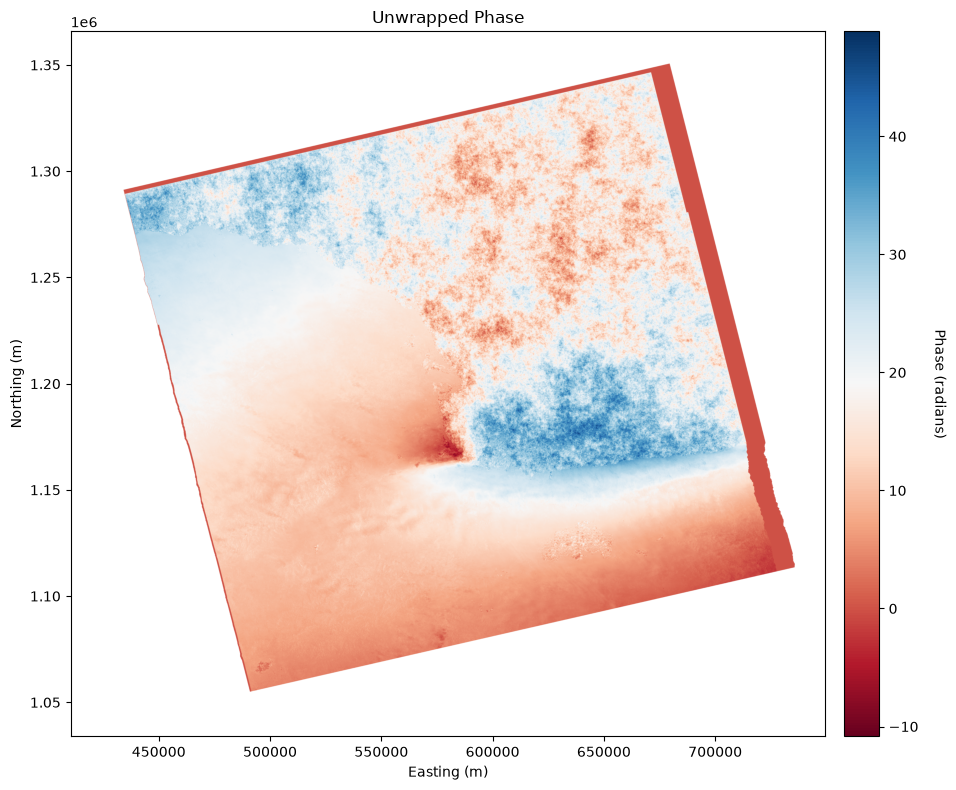

In [13]:
file_path = "output_files/phase.tif"

phase, extent = loadData(file_path)

# Plot
fig, ax = plt.subplots(1, 1, figsize=(10, 8))

im = ax.imshow(phase, cmap='RdBu', aspect='auto',
               extent=extent)
ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')
ax.set_title(f'Unwrapped Phase')

cbar = plt.colorbar(im, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('Phase (radians)', rotation=270, labelpad=20)

plt.tight_layout()
plt.show()

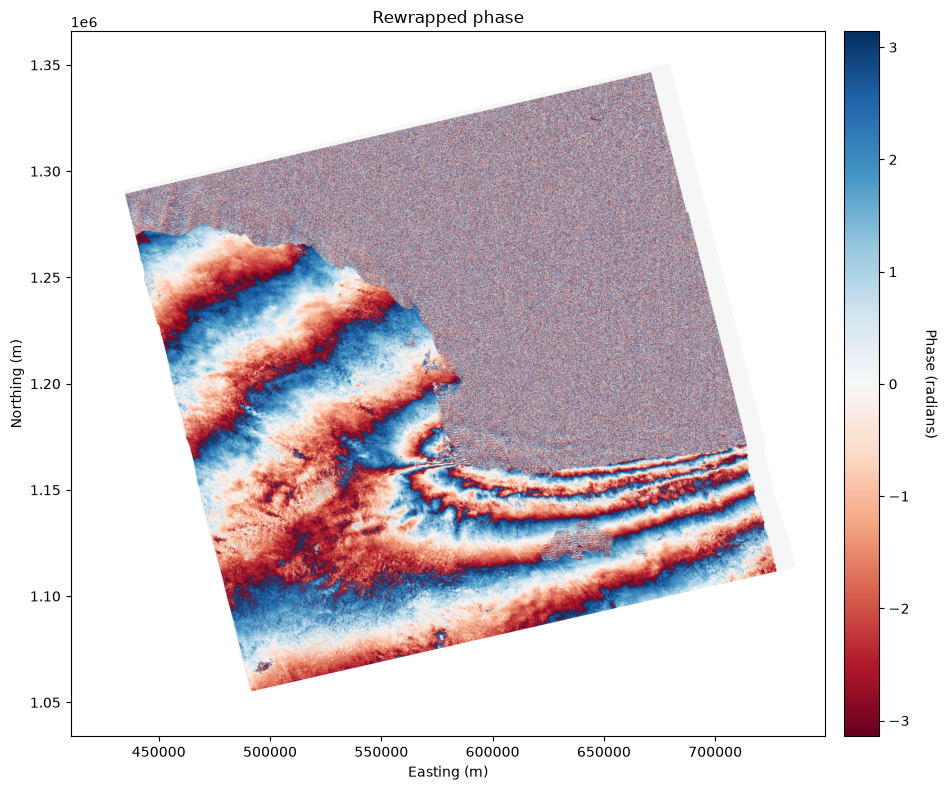

In [14]:
file_path = "output_files/wrapped_phase.tif"

wrapped_phase, extent = loadData(file_path)

fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    
im = ax.imshow(wrapped_phase, cmap='RdBu', aspect='auto',
                   extent=extent)
ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')
ax.set_title(f'Rewrapped phase')
    
cbar = plt.colorbar(im, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('Phase (radians)', rotation=270, labelpad=20)
    
plt.tight_layout()
plt.show()

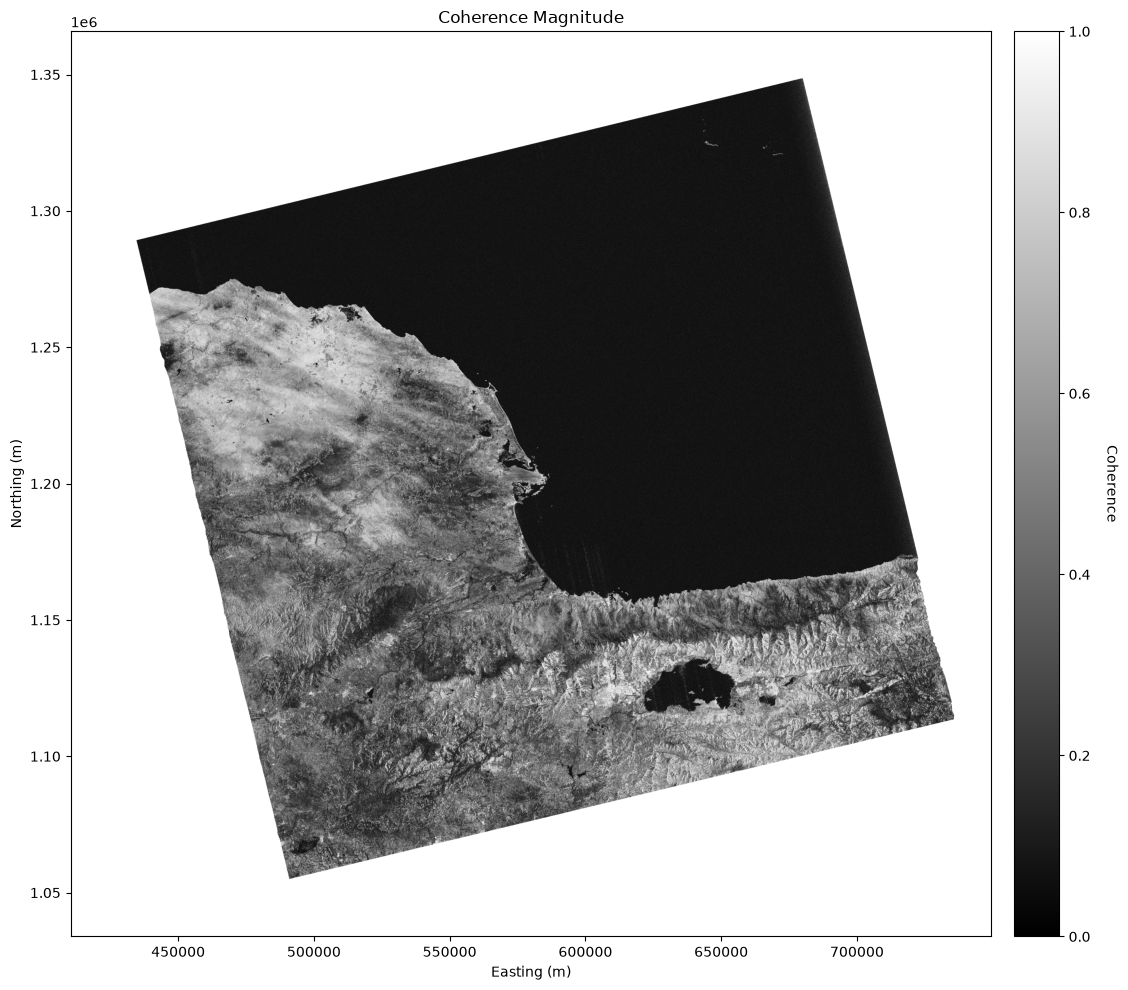

In [15]:
file_path = "output_files/coherence.tif"

coherence, extent = loadData(file_path)

fig, ax = plt.subplots(1, 1, figsize=(12, 10))

im = ax.imshow(coherence, cmap='gray', vmin=0, vmax=1, aspect='auto',
               extent=extent)
ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')
ax.set_title(f'Coherence Magnitude')

cbar = plt.colorbar(im, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('Coherence', rotation=270, labelpad=20)

plt.tight_layout()
plt.show()

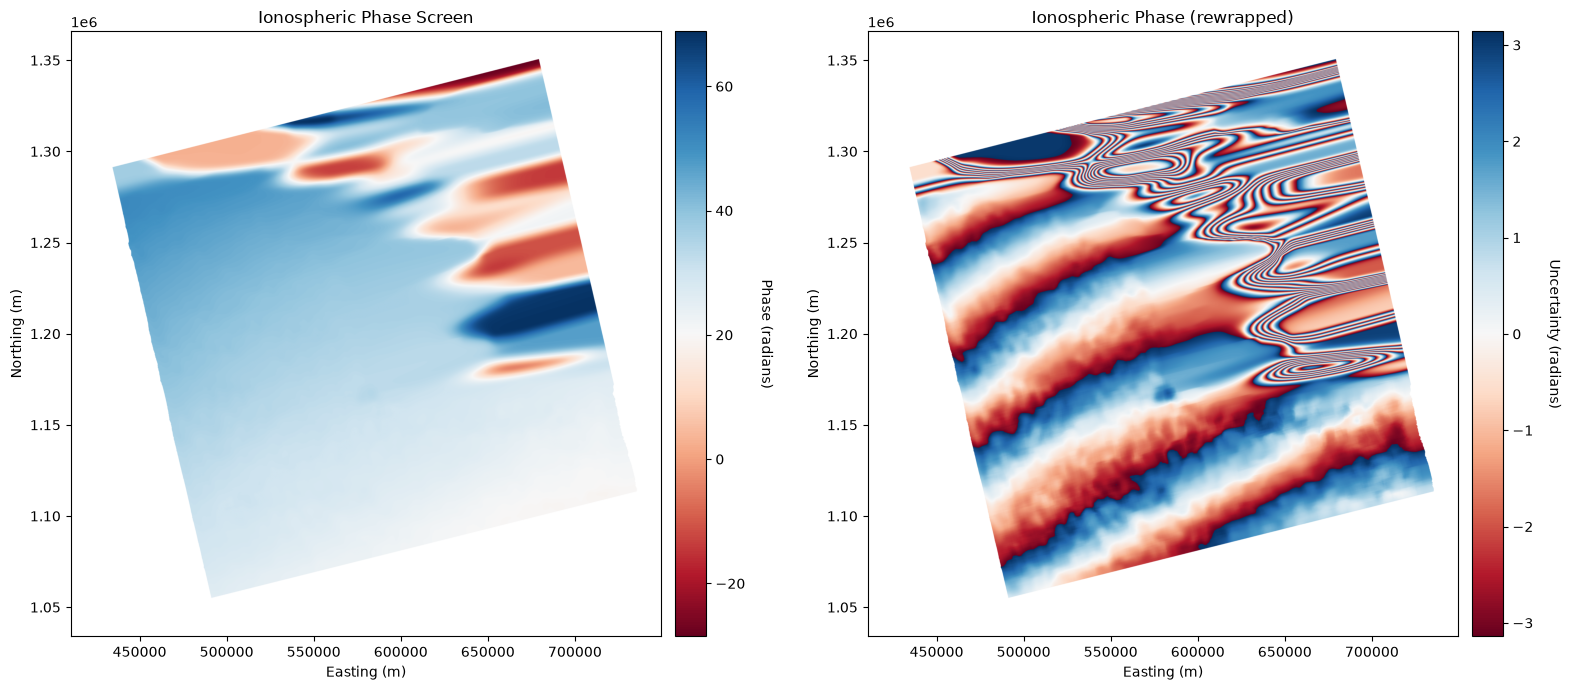

In [16]:
file_path = "output_files/iono.tif"

iono, extent = loadData(file_path)


# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Ionosphere
im1 = axes[0].imshow(iono, cmap='RdBu', aspect='auto',
                     extent=extent)
axes[0].set_xlabel('Easting (m)')
axes[0].set_ylabel('Northing (m)')
axes[0].set_title('Ionospheric Phase Screen')
cbar1 = plt.colorbar(im1, ax=axes[0], orientation='vertical', pad=0.02)
cbar1.set_label('Phase (radians)', rotation=270, labelpad=20)

# Uncertainty
im2 = axes[1].imshow(np.angle(np.exp(1J*iono)), cmap='RdBu', aspect='auto',
                     extent=extent)
axes[1].set_xlabel('Easting (m)')
axes[1].set_ylabel('Northing (m)')
axes[1].set_title('Ionospheric Phase (rewrapped)')
cbar2 = plt.colorbar(im2, ax=axes[1], orientation='vertical', pad=0.02)
cbar2.set_label('Uncertainty (radians)', rotation=270, labelpad=20)

plt.tight_layout()
plt.show()

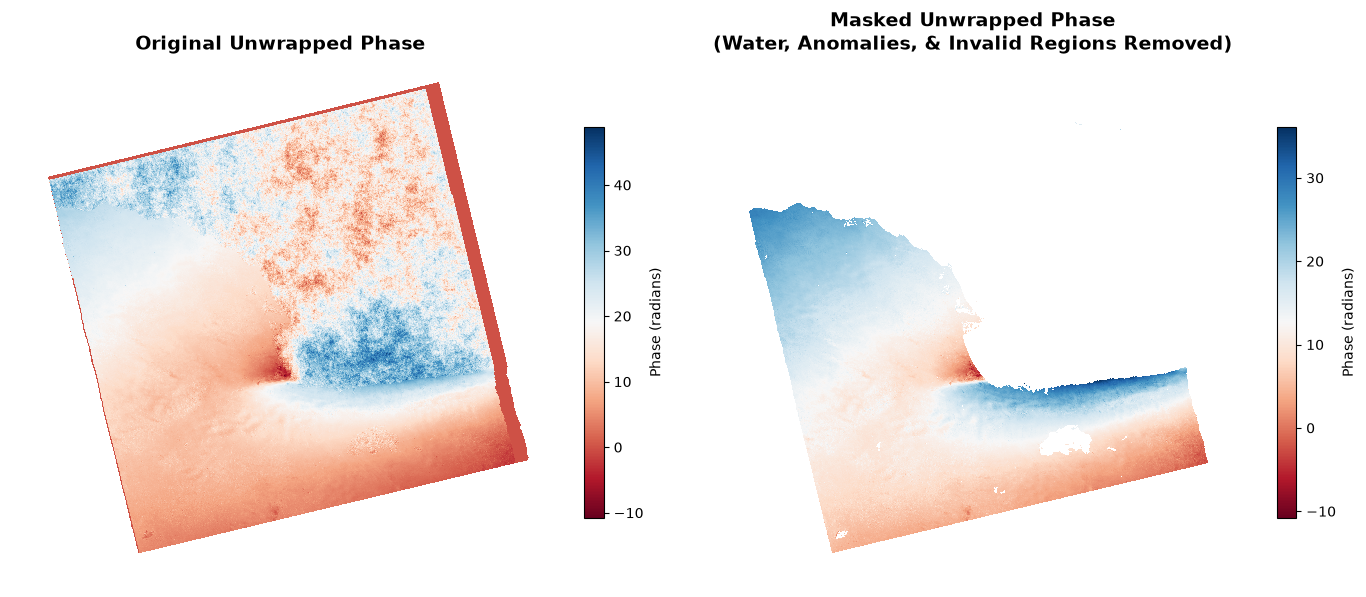

In [17]:
file_path = "output_files/phase_masked.tif"

phase_masked, extent = loadData(file_path)

# Set up a 1x2 plotting grid
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

# 1. Plot the original unmasked phase
im1 = axes[0].imshow(phase, cmap='RdBu', interpolation='nearest')
axes[0].set_title("Original Unwrapped Phase", fontsize=14, fontweight='bold')
axes[0].axis('off')
fig.colorbar(im1, ax=axes[0], label='Phase (radians)', shrink=0.7)

# 2. Plot the masked phase (NaN values will automatically show as transparent/blank)
im2 = axes[1].imshow(phase_masked, cmap='RdBu', interpolation='nearest')
axes[1].set_title("Masked Unwrapped Phase\n(Water, Anomalies, & Invalid Regions Removed)", 
                  fontsize=14, fontweight='bold')
axes[1].axis('off')
fig.colorbar(im2, ax=axes[1], label='Phase (radians)', shrink=0.7)

# Optimize spacing and display
plt.tight_layout()
plt.show()

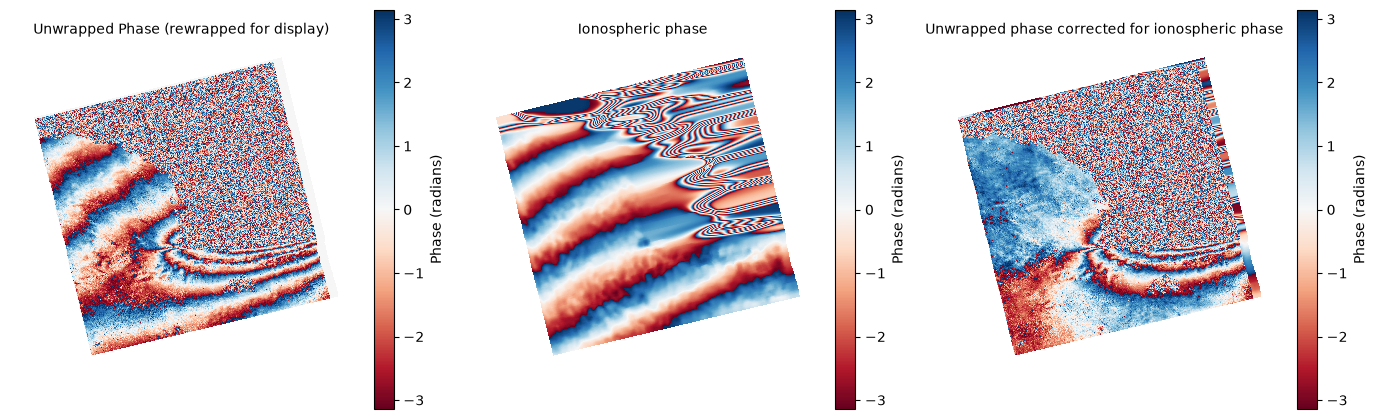

In [18]:
file_path = "output_files/phase_iono_corrected.tif"

phase_iono_corrected_masekd, extent = loadData(file_path)

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14, 6))

# 1. Plot the original unmasked phase
im1 = axes[0].imshow(np.angle(np.exp(1J*phase)), cmap='RdBu', interpolation='nearest')
axes[0].set_title("Unwrapped Phase (rewrapped for display)", fontsize=10)
axes[0].axis('off')
fig.colorbar(im1, ax=axes[0], label='Phase (radians)', shrink=0.7)

# 2. Plot the masked phase (NaN values will automatically show as transparent/blank)
im2 = axes[1].imshow(np.angle(np.exp(1J*iono)), cmap='RdBu', interpolation='nearest')
axes[1].set_title("Ionospheric phase", 
                  fontsize=10)
axes[1].axis('off')
fig.colorbar(im2, ax=axes[1], label='Phase (radians)', shrink=0.7)

im3 = axes[2].imshow(np.angle(np.exp(1J*phase_iono_corrected_masekd)), cmap='RdBu', interpolation='nearest')
axes[2].set_title("Unwrapped phase corrected for ionospheric phase", 
                  fontsize=10 )
axes[2].axis('off')
fig.colorbar(im3, ax=axes[2], label='Phase (radians)', shrink=0.7)


# Optimize spacing and display
plt.tight_layout()
plt.show()

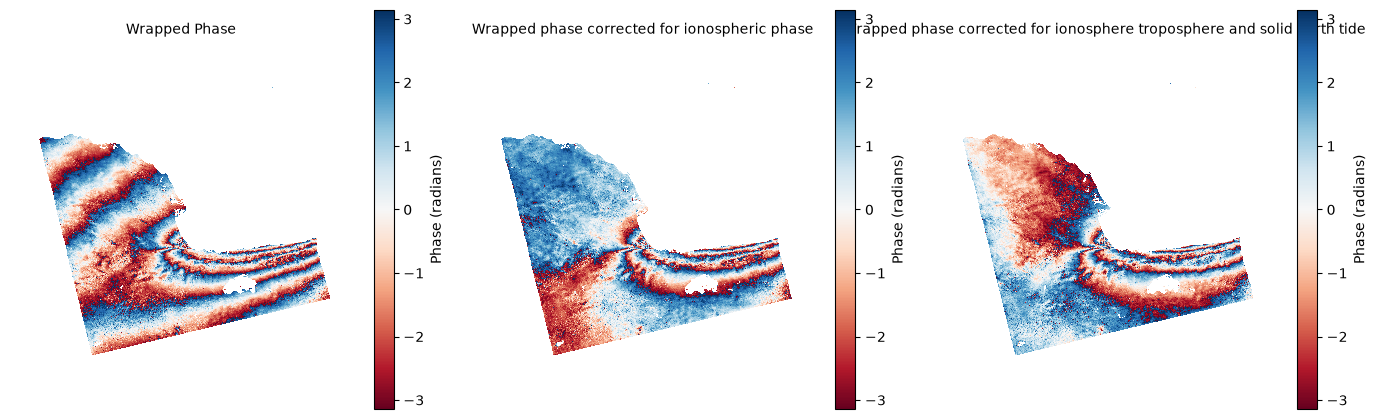

In [19]:
file_path = "output_files/phase_iono_corrected_masekd.tif"

phase_iono_corrected_masekd, extent = loadData(file_path)


file_path = "output_files/phase_corrected_masked.tif"

phase_corrected_masked, extent = loadData(file_path)

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14, 6))

# 1. Plot the original unmasked phase
im1 = axes[0].imshow(np.angle(np.exp(1J*phase_masked)), cmap='RdBu', interpolation='nearest')
axes[0].set_title("Wrapped Phase", fontsize=10)
axes[0].axis('off')
fig.colorbar(im1, ax=axes[0], label='Phase (radians)', shrink=0.7)

# 2. Plot the masked phase (NaN values will automatically show as transparent/blank)
im2 = axes[1].imshow(np.angle(np.exp(1J*phase_iono_corrected_masekd)), cmap='RdBu', interpolation='nearest')
axes[1].set_title("Wrapped phase corrected for ionospheric phase", 
                  fontsize=10)
axes[1].axis('off')
fig.colorbar(im2, ax=axes[1], label='Phase (radians)', shrink=0.7)

im3 = axes[2].imshow(np.angle(np.exp(1J*phase_corrected_masked)), cmap='RdBu', interpolation='nearest')
axes[2].set_title("Wrapped phase corrected for ionosphere troposphere and solid earth tide", 
                  fontsize=10 )
axes[2].axis('off')
fig.colorbar(im3, ax=axes[2], label='Phase (radians)', shrink=0.7)


# Optimize spacing and display
plt.tight_layout()
plt.show()

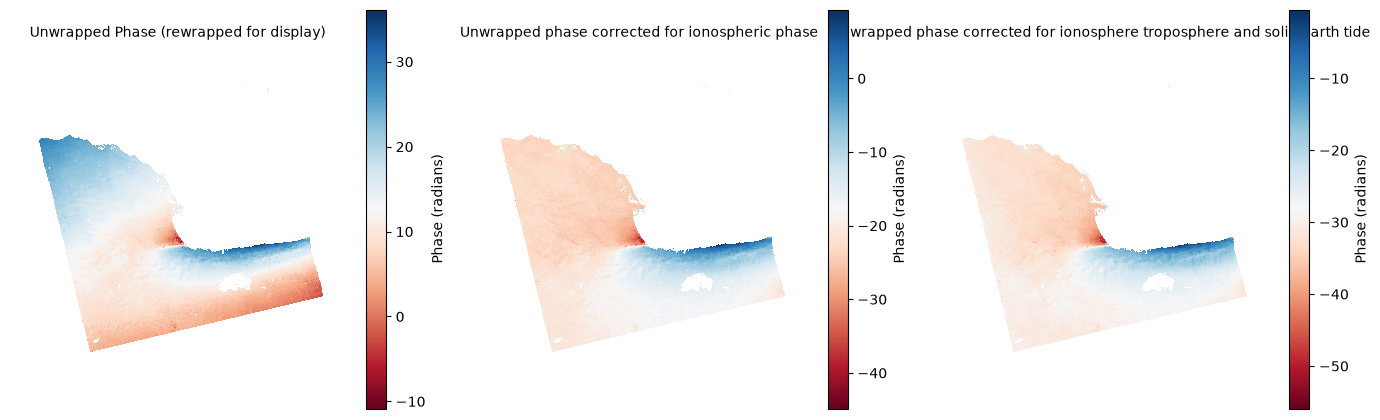

In [20]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14, 6))

# 1. Plot the original unmasked phase
im1 = axes[0].imshow((phase_masked), cmap='RdBu', interpolation='nearest', )
axes[0].set_title("Unwrapped Phase (rewrapped for display)", fontsize=10)
axes[0].axis('off')
fig.colorbar(im1, ax=axes[0], label='Phase (radians)', shrink=0.7)

# 2. Plot the masked phase (NaN values will automatically show as transparent/blank)
im2 = axes[1].imshow((phase_iono_corrected_masekd), cmap='RdBu', interpolation='nearest', )
axes[1].set_title("Unwrapped phase corrected for ionospheric phase", 
                  fontsize=10)
axes[1].axis('off')
fig.colorbar(im2, ax=axes[1], label='Phase (radians)', shrink=0.7)

im3 = axes[2].imshow((phase_corrected_masked), cmap='RdBu', interpolation='nearest', )
axes[2].set_title("Unwrapped phase corrected for ionosphere troposphere and solid earth tide", 
                  fontsize=10 )
axes[2].axis('off')
fig.colorbar(im3, ax=axes[2], label='Phase (radians)', shrink=0.7)


# Optimize spacing and display
plt.tight_layout()
plt.show()